# Project 2: Getting Started 

This notebook is intended to help you get started with the dataset you need to use for Project 2 of the course. 

* **Source:** Ursu (2018), which says to download data from Kaggle: https://www.kaggle.com/competitions/expedia-personalized-sort/data

## Variables in the dataset 

| srch_id | Integer | The ID of the search | 
| ------- | ------- | -------------------- |
| date_time | Date/time | Date and time of the search |
| site_id | Integer | ID of the Expedia point of sale (i.e. Expedia.com, Expedia.co.uk, Expedia.co.jp, ..) |
| visitor_location_country_id  | Integer | The ID of the country the customer is located |
| visitor_hist_starrating | Float | The mean star rating of hotels the customer has previously purchased; null signifies there is no purchase history on the customer |
| visitor_hist_adr_usd | Float | The mean price per night (in US$) of the hotels the customer has previously purchased; null signifies there is no purchase history on the customer |
| prop_country_id | Integer | The ID of the country the hotel is located in |
| prop_id | Integer | The ID of the hotel |
| prop_starrating | Integer | The star rating of the hotel, from 1 to 5, in increments of 1.  A 0 indicates the property has no stars, the star rating is not known or cannot be publicized. |
| prop_review_score | Float | The mean customer review score for the hotel on a scale out of 5, rounded to 0.5 increments. A 0 means there have been no reviews, null that the information is not available. |
| prop_brand_bool | Integer | +1 if the hotel is part of a major hotel chain; 0 if it is an independent hotel |
| prop_location_score1 | Float | A (first) score outlining the desirability of a hotel’s location |
| prop_location_score2 | Float | A (second) score outlining the desirability of the hotel’s location |
| prop_log_historical_price |  Float | The logarithm of the mean price of the hotel over the last trading period. A 0 will occur if the hotel was not sold in that period. |
| position | Integer | Hotel position on Expedia's search results page. This is only provided for the training data, but not the test data. |
| price_usd | Float | Displayed price of the hotel for the given search.  Note that different countries have different conventions regarding displaying taxes and fees and the value may be per night or for the whole stay | 
| promotion_flag | Integer | +1 if the hotel had a sale price promotion specifically displayed |
| gross_booking_usd | Float | Total value of the transaction.  This can differ from the price_usd due to taxes, fees, conventions on multiple day bookings and purchase of a room type other than the one shown in the search |
| srch_destination_id  | Integer | ID of the destination where the hotel search was performed |
| srch_length_of_stay | Integer | Number of nights stay that was searched |
| srch_booking_window | Integer | Number of days in the future the hotel stay started from the search date |
| srch_adults_count | Integer | The number of adults specified in the hotel room |
| srch_children_count | Integer | The number of (extra occupancy) children specified in the hotel room |
| srch_room_count | Integer | Number of hotel rooms specified in the search |
| srch_saturday_night_bool | Boolean | +1 if the stay includes a Saturday night, starts from Thursday with a length of stay is less than or equal to 4 nights (i.e. weekend); otherwise 0 |
| srch_query_affinity_score | Float | The log of the probability a hotel will be clicked on in Internet searches (hence the values are negative)  A null signifies there are no data (i.e. hotel did not register in any searches) |
| orig_destination_distance | Float | Physical distance between the hotel and the customer at the time of search. A null means the distance could not be calculated. |
| random_bool | Boolean | +1 when the displayed sort was random, 0 when the normal sort order was displayed |
| comp1_rate | Integer | +1 if Expedia has a lower price than competitor 1 for the hotel; 0 if the same; -1 if Expedia’s price is higher than competitor 1; null signifies there is no competitive data |
| comp1_inv  | Integer | +1 if competitor 1 does not have availability in the hotel; 0 if both Expedia and competitor 1 have availability; null signifies there is no competitive data |
| comp1_rate_percent_diff | Float | The absolute percentage difference (if one exists) between Expedia and competitor 1’s price (Expedia’s price the denominator); null signifies there is no competitive data |
| comp`X`_rate | | for `X` = 2,...,8: as `X`=1 | 
| comp`X`_inv   | | for `X` = 2,...,8: as `X`=1  | 
| comp`X`_rate_percent_diff | | for `X` = 2,...,8: as `X`=1  | 


# Read in data

In [119]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.formula.api import ols
import seaborn as sns
from scipy.optimize import minimize

In [120]:
# All 54 columns take about 9 GB of memory at the peak. These 14 take about 2.5 GB.
# To read everything, set cols = None. Add a column to the list if you need it.
cols = ['srch_id', 'position', 'random_bool', 'click_bool', 'booking_bool', 'price_usd',
        'prop_starrating', 'prop_review_score', 'prop_brand_bool', 'prop_location_score1', 'prop_location_score2',
        'prop_log_historical_price', 'promotion_flag', 'srch_children_count', 'srch_length_of_stay']
dat = pd.read_parquet('train.parquet', columns=cols)

In [121]:
dat.head(3)

,srch_id,position,random_bool,click_bool,booking_bool,price_usd,prop_starrating,prop_review_score,prop_brand_bool,prop_location_score1,prop_location_score2,prop_log_historical_price,promotion_flag,srch_children_count,srch_length_of_stay
0,1,27,1,0,0,104.77,3,3.5,1,2.83,0.0438,4.95,0,0,1
1,1,26,1,0,0,170.74,4,4.0,1,2.20,0.0149,5.03,0,0,1
2,1,21,1,0,0,179.80,3,4.5,1,2.20,0.0245,4.92,0,0,1


In [122]:
dat.set_index(['srch_id', 'position']).sort_index()[['click_bool', 'booking_bool', 'price_usd', 'prop_starrating']].head(40)

click_bool  booking_bool  price_usd  prop_starrating
srch_id position                                                      
1       1                  0             0     139.70                4
        2                  0             0     210.84                3
        3                  0             0     150.05                4
        4                  0             0     143.58                4
        6                  0             0     191.44                4
        7                  0             0     195.32                4
        8                  0             0     115.12                4
        10                 0             0     280.69                4
        12                 0             0     128.06                2
        13                 1             1     100.89                2
        15                 0             0     138.40                3
        18                 0             0     129.35                3
        19                 0             0     100.89                3
        20                 0             0     190.14                3
        21                 0             0     179.80                3
        23                 0             0     152.63                4
        24                 0             0     181.09                3
        26                 0             0     170.74                4
        27                 0             0     104.77                3
        28                 0             0     122.88                3
        29                 0             0     190.14                3
        31                 0             0     100.89                2
        32                 0             0     115.12                2
        33                 0             0     104.77                2
        34                 0             0     602.77                2
        35                 0             0      85.37                2
        36                 0             0     138.40                3
        37                 0             0     120.29                3
4       1                  0             0     159.00                3
        2                  0             0     219.00                3
        3                  0             0     365.00                4
        4                  0             0     329.00                3
        6                  0             0     330.00                4
        7                  0             0     135.00                2
        8                  0             0     189.00                2
        9                  0             0     329.00                4
        10                 0             0     335.00                4
        12                 0             0     525.00                5
        13                 0             0     408.00                4
        14                 0             0     255.00                4

## Perform some simple calculations to illustrate how it works

In [123]:
# a 'srch_id' is one unique session. the consumer can click more or less hotels. 
dat.groupby('srch_id')[['click_bool', 'booking_bool']].sum().mean()

click_bool      1.111002
booking_bool    0.692618
dtype: float64

<Axes: xlabel='random_bool'>

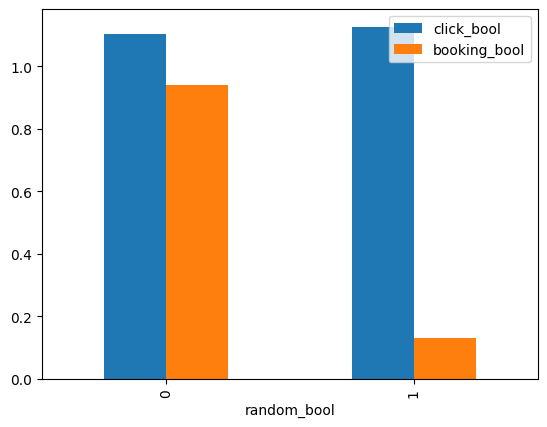

In [124]:
# there are stark differences across the random and non-random subsamples 
dat.groupby(['random_bool', 'srch_id'])[['click_bool', 'booking_bool']].sum().groupby('random_bool').mean().plot.bar()

## Across position in the search list 

In [125]:
dat.groupby('position')[['click_bool', 'booking_bool', 'price_usd', 'prop_starrating']].mean().round(2)

,click_bool,booking_bool,price_usd,prop_starrating
position,,,,
1,0.19,0.14,291.27,3.45
2,0.13,0.09,276.88,3.39
3,0.11,0.07,265.81,3.35
4,0.09,0.06,265.64,3.32
5,0.02,0.01,178.27,3.21
6,0.07,0.05,266.41,3.28
7,0.06,0.04,262.49,3.26
8,0.05,0.03,270.71,3.24
9,0.05,0.03,264.54,3.23


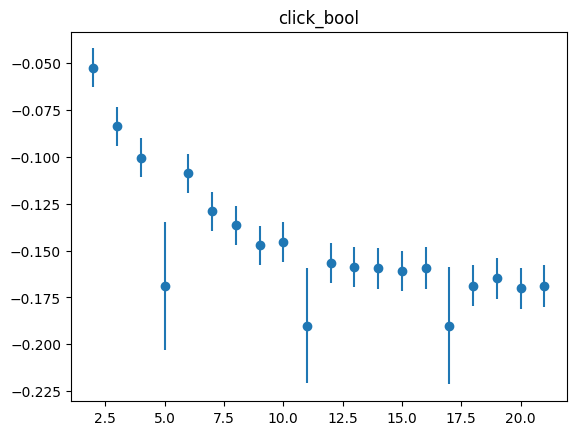

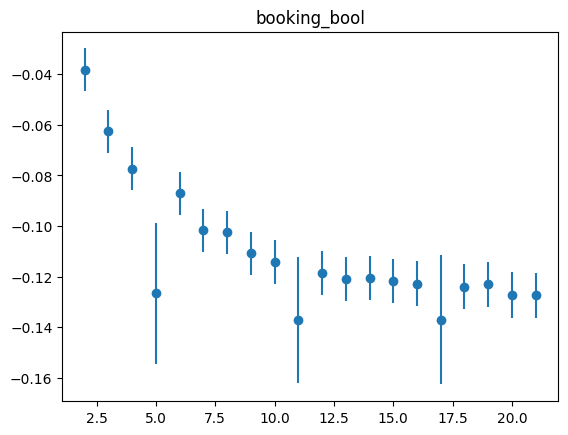

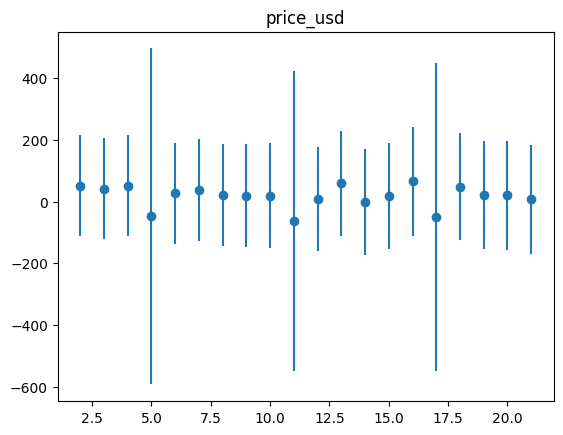

In [126]:
# let's show the effect of position on the different outcomes as coefficient estimates on dummies with error bars 

# subsample 1% of the sessions
frac = 0.01 
srch_ids = dat['srch_id'].drop_duplicates().sample(frac=frac).sort_values().values
dat_sub = dat[dat['srch_id'].isin(srch_ids)]
dat_sub = dat_sub.query('position <= 21')

def plot_position_dummies(mod): 
    idx_dummies = [c for c in mod.params.index if 'position' in c]
    p_ = mod.params[idx_dummies]
    conf_int = mod.conf_int().loc[idx_dummies]
    plt.errorbar(np.arange(2, p_.size+2), p_.values, yerr=(p_-conf_int[0], conf_int[1]-p_), fmt='o')

# click_bool
mod = ols('click_bool ~ C(position)', data=dat_sub).fit()
plot_position_dummies(mod)
plt.title('click_bool')
plt.show()

# booking_bool
mod = ols('booking_bool ~ C(position)', data=dat_sub).fit()
plot_position_dummies(mod)
plt.title('booking_bool')
plt.show()

# price_usd
mod = ols('price_usd ~ C(position)', data=dat_sub).fit()
plot_position_dummies(mod)
plt.title('price_usd')
plt.show();

# clean up data

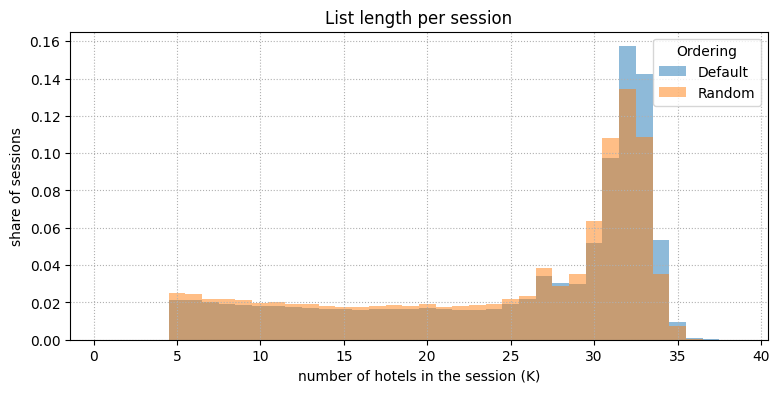

sessions with fewer than 5 hotels: 0.0%
sessions with fewer than 7 hotels: 4.5%
sessions with fewer than 10 hotels: 10.5%
sessions with fewer than 15 hotels: 19.5%


In [127]:
n_list = dat.groupby('srch_id').agg(n_hotels=('position', 'count'),
                                    random_bool=('random_bool', 'max'))

bins = np.arange(0.5, n_list['n_hotels'].max() + 1.5, 1)    # one bar per list length
fig, ax = plt.subplots(figsize=(9, 4))
for rb, name in [(0, 'Default'), (1, 'Random')]:
    ax.hist(n_list.loc[n_list.random_bool == rb, 'n_hotels'], bins=bins,
            density=True, alpha=0.5, label=name)
ax.set_xlabel('number of hotels in the session (K)')
ax.set_ylabel('share of sessions')
ax.set_title('List length per session')
ax.legend(title='Ordering'); ax.grid(linestyle=':')
plt.show()

# how much each cut-off would drop
for k in [5, 7, 10, 15]:
    print(f'sessions with fewer than {k} hotels: {(n_list.n_hotels < k).mean():.1%}')

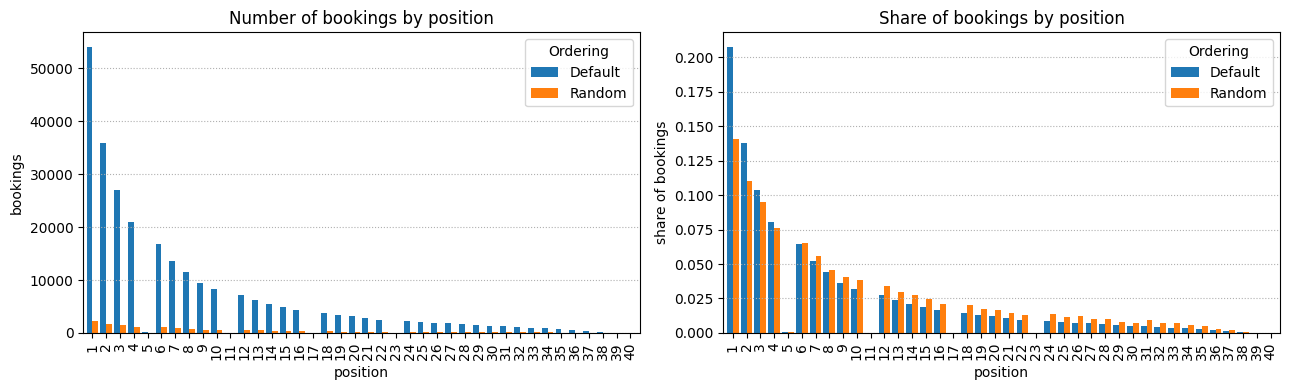

Share of bookings at position 30 or higher:
random_bool
Default    1.4109
Random     2.3793
dtype: float64


In [128]:
b = dat[dat['booking_bool'] == 1]
counts = b.groupby(['position', 'random_bool']).size().unstack('random_bool').fillna(0)
counts = counts.rename(columns={0: 'Default', 1: 'Random'})
shares = counts / counts.sum()                      # share of each ordering's bookings at each position

fig, axs = plt.subplots(1, 2, figsize=(13, 4))

counts.plot(kind='bar', ax=axs[0], width=0.85)
axs[0].set_title('Number of bookings by position'); axs[0].set_ylabel('bookings')

shares.plot(kind='bar', ax=axs[1], width=0.85)
axs[1].set_title('Share of bookings by position'); axs[1].set_ylabel('share of bookings')

for ax in axs:
    ax.set_xlabel('position'); ax.grid(axis='y', linestyle=':')
    ax.legend(title='Ordering')
plt.tight_layout(); plt.show()

print('Share of bookings at position 30 or higher:')
print(((counts[counts.index >= 33].sum() / counts.sum())*100).round(4))

## Pr(buy | search, random)

Arguably, the two most important graphs in Ursu relate to Pr(click) and Pr(buy|click). 

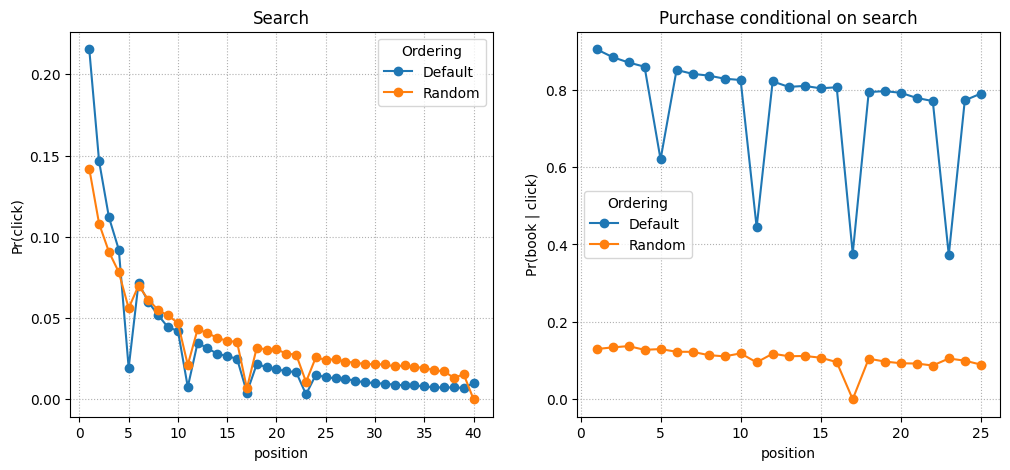

In [129]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Pr(click)
dat.groupby(['random_bool', 'position'])['click_bool'].mean().unstack('random_bool').rename(columns={0: 'Default', 1: 'Random'}).plot(marker='o', ax=axs[0])
axs[0].legend(title='Ordering'); axs[0].set_ylabel('Pr(click)'); axs[0].grid(axis='both', linestyle=':');
axs[0].set_title('Search'); 

# next: we condition on clicking (i.e. searching) and being in the top 25 positions (the last are very noisy)
df = dat.query('(click_bool == 1) & (position <= 25)')

# Pr(buy | click): the click-through rate (CTR)
df.groupby(['random_bool', 'position'])['booking_bool'].mean().unstack('random_bool').rename(columns={0: 'Default', 1: 'Random'}).plot(marker='o', ax=axs[1])
axs[1].legend(title='Ordering');
axs[1].set_ylabel('Pr(book | click)'); axs[1].grid(axis='both', linestyle=':'); 
axs[1].set_title('Purchase conditional on search');

## Checking if the random ranking is default

We remove sessions with less than 25 listning to be able to compare data with similar length. Otherwise sessions with fewer listnings will influence the mean of earlier positions making the it look like the position influences the variables more than it actually does. 

We could consider whether we wanted to balance the dataset (remove sessions with few listnings and observations with very high position. But it should not matter much for estimation)

In [130]:
### Code to balance the data set ###

K_max = 100   # keep positions 1-29, i.e. drop 30 and higher
K_min = 25    # keep sessions with at least 5 hotels

n_sessions0 = dat['srch_id'].nunique()

# 1. sessions that booked a hotel we are about to drop: remove the whole session
booked_deep = dat.loc[(dat['booking_bool'] == 1) & (dat['position'] > K_max), 'srch_id'].unique()

# 2. drop hotels at position 30 or higher, and those sessions
dat_bal = dat[(dat['position'] <= K_max) & (~dat['srch_id'].isin(booked_deep))].copy()

# 3. drop sessions with fewer than 5 hotels (counted after the cut)
n_hotels = dat_bal.groupby('srch_id')['position'].transform('count')
dat_bal = dat_bal[n_hotels >= K_min]

# what was dropped
print(f"sessions dropped for a booking at position > {K_max}: {len(booked_deep)} ({len(booked_deep)/n_sessions0:.2%})")
print(f"sessions left: {dat_bal['srch_id'].nunique()} of {n_sessions0} ({dat_bal['srch_id'].nunique()/n_sessions0:.1%})")
print(f"rows left: {len(dat_bal)} of {len(dat)} ({len(dat_bal)/len(dat):.1%})")

sessions dropped for a booking at position > 100: 0 (0.00%)
sessions left: 253771 of 399344 (63.5%)
rows left: 7874634 of 9917530 (79.4%)


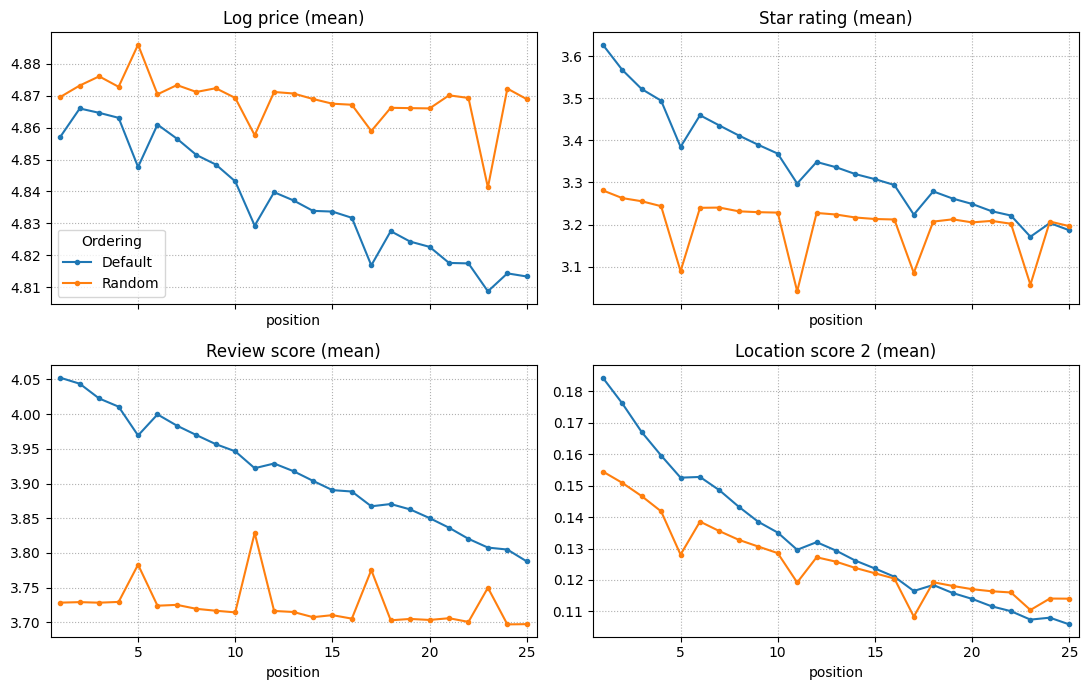

In [131]:
attrs = {'log_price': 'Log price (mean)',
         'prop_starrating': 'Star rating (mean)',
         'prop_review_score': 'Review score (mean)',
         'prop_location_score2': 'Location score 2 (mean)'}

d = dat_bal.query('position <= 25').copy()
d['log_price'] = np.log(d['price_usd'].where(d['price_usd'] > 0))  # zero prices -> NaN

fig, axs = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
axs = axs.flatten()

for ax, (col, label) in zip(axs, attrs.items()):
    for rb, name in [(0, 'Default'), (1, 'Random')]:
        m = d[d.random_bool == rb].groupby('position')[col].mean()
        ax.plot(m.index, m, marker='o', ms=3, label=name)
    ax.set_title(label); ax.set_xlabel('position'); ax.grid(linestyle=':')
    ax.set_xlim(0.5, 25.5)

axs[0].legend(title='Ordering')
plt.tight_layout(); plt.show()

# Micro likelihood

As in PS8 and PS9, the data go in long format, indexed by $(i, j)$: $i$ is the session (`srch_id`) and $j$ the listing's position in it. Each session also gets a row for the outside option, $j = 0$.

$j$ is a label, not a counter: almost every session skips some positions, so never assume that $j$ runs $0, 1, \dots, J$. The position also enters as a regressor, $\text{Rank}_{ij}$, in the column `position_num`.

In [ ]:
frac = 0.01 # the share of sessions to keep: the full data are slow to estimate on
price_min = dat.groupby('srch_id')['price_usd'].min()
idx_i = price_min.index[price_min > 0] # a few listings have a price of zero, so log price fails: drop their sessions
idx_i = pd.Series(idx_i).sample(frac=frac, random_state=1).values
I_sample = dat['srch_id'].isin(idx_i)
df = dat[I_sample]
df = df.set_index(['srch_id', 'position']).sort_index()
df.index.names = ['i', 'j']
df = df.select_dtypes('number') # numbers only, because the outside rows will be zeros

# the regressors, built before the outside rows go in, so that those rows get zeros
df['log_price'] = np.log(df['price_usd'])
df['stars'] = df['prop_starrating'].astype(float)
df['position_num'] = df.index.get_level_values('j').astype(float) # Rank_ij
df['position_log'] = np.log(df['position_num']) # log(Rank_ij)
df['constant'] = 1.0

### Different position setups ###
# linear position 
df['position_num'] = df.index.get_level_values('j').astype(float) # Rank_ij
#log position
df['position_log'] = np.log(df['position_num']) # log(Rank_ij)
# dummy for each position for testing
pos = df.index.get_level_values('j').to_series(index=df.index).clip(upper=26)   # 26 = "26 or lower"
dummies = pd.get_dummies(pos, prefix='pos', dtype=float).drop(columns='pos_1')   # position 1 = base
df = df.join(dummies)

### regressors for combining random and default sessions
# Dummy for default session (seperate the oversampling /level effect)
df['default_dum'] = (df['random_bool'] == 0).astype(float)
# interaction term between default session and log position (to allow for different position effects in the two subsamples)
df['default_dum_x_position_log'] = df['default_dum'] * df['position_log']
#interaction term between default session and stars
df['default_dum_x_stars'] = df['default_dum'] * df['stars']

# the outside option: one row per session, j = 0, with every column zero, so delta_i0 = 0
idx_outside = pd.MultiIndex.from_product([df.index.get_level_values('i').unique(), [0]], names=['i', 'j'])
df = df.reindex(df.index.append(idx_outside), fill_value=0).sort_index()

I_outside = df.index.get_level_values('j') == 0
booked_any = df.groupby(level='i')['booking_bool'].transform('max') # 1 if the session booked a hotel
booked_any = booked_any[I_outside]
df.loc[I_outside, 'click_bool'] = 1 # the outside option is always "searched", as in PS8
df.loc[I_outside, 'booking_bool'] = 1 - booked_any # and it is chosen when no hotel is booked

# make random_ bool for outside option = 1 if session is random rank (right now it is 0)
df['random_bool'] = df.groupby(level='i')['random_bool'].transform('max')

assert (df.groupby(level='i')['booking_bool'].sum() == 1).all() # exactly one choice per session

df.head(10)

random_bool  click_bool  booking_bool  price_usd  prop_starrating  \
i  j                                                                       
53 0             0           1             0        0.0                0   
   1             0           0             0      163.0                4   
   2             0           0             0      229.0                4   
   3             0           0             0      203.0                4   
   4             0           1             1      151.0                4   
   6             0           0             0      219.0                4   
   7             0           0             0      179.0                4   
   8             0           0             0      180.0                5   
   9             0           0             0      179.0                4   
   10            0           0             0      139.0                4   

       prop_review_score  prop_brand_bool  prop_location_score1  \
i  j                                                              
53 0                 0.0                0                  0.00   
   1                 4.5                1                  3.87   
   2                 4.5                1                  3.87   
   3                 5.0                1                  3.58   
   4                 4.5                1                  3.91   
   6                 4.5                1                  3.97   
   7                 4.5                1                  3.56   
   8                 4.5                1                  3.87   
   9                 4.5                1                  3.93   
   10                4.5                1                  2.56   

       prop_location_score2  prop_log_historical_price  ...  pos_20  pos_21  \
i  j                                                    ...                   
53 0                 0.0000                       0.00  ...     0.0     0.0   
   1                 0.2129                       5.61  ...     0.0     0.0   
   2                 0.2053                       5.68  ...     0.0     0.0   
   3                 0.0480                       5.52  ...     0.0     0.0   
   4                 0.1399                       5.35  ...     0.0     0.0   
   6                 0.1274                       5.50  ...     0.0     0.0   
   7                 0.0531                       5.27  ...     0.0     0.0   
   8                 0.2050                       5.42  ...     0.0     0.0   
   9                 0.1274                       5.50  ...     0.0     0.0   
   10                0.0298                       5.40  ...     0.0     0.0   

       pos_22  pos_23  pos_24  pos_25  pos_26  default_dum  \
i  j                                                         
53 0      0.0     0.0     0.0     0.0     0.0          0.0   
   1      0.0     0.0     0.0     0.0     0.0          1.0   
   2      0.0     0.0     0.0     0.0     0.0          1.0   
   3      0.0     0.0     0.0     0.0     0.0          1.0   
   4      0.0     0.0     0.0     0.0     0.0          1.0   
   6      0.0     0.0     0.0     0.0     0.0          1.0   
   7      0.0     0.0     0.0     0.0     0.0          1.0   
   8      0.0     0.0     0.0     0.0     0.0          1.0   
   9      0.0     0.0     0.0     0.0     0.0          1.0   
   10     0.0     0.0     0.0     0.0     0.0          1.0   

       default_dum_x_position_log  default_dum_x_stars  
i  j                                                    
53 0                     0.000000                  0.0  
   1                     0.000000                  4.0  
   2                     0.693147                  4.0  
   3                     1.098612                  4.0  
   4                     1.386294                  4.0  
   6                     1.791759                  4.0  
   7                     1.945910                  4.0  
   8                     2.079442                  5.0  
   9                     

## The logit

The likelihood is the one in PS9 with $\gamma = 0$, so $\hat\beta$ estimates $\theta = \beta - \gamma$. `groupby(level='i')` does the sums within each session. `.transform('max')` returns the session's maximum on every row of the session, so it can be subtracted from `v`, while `.max()` would return one number per session.

In [133]:
def loglike(beta, X, I_chosen):
    '''Minus the average log-likelihood of the logit.'''
    v = X @ beta
    v -= v.groupby(level='i').transform('max') # for numerical stability
    log_probs = v - np.log(np.exp(v).groupby(level='i').transform('sum'))
    return -np.mean(log_probs[I_chosen].values)


# Testing different descision for the setup of the baseline model
 - examines how position should enter in the estimation (log or linear)
 - examines what data to use (random ranking, defualt ranking or both)

### Testing how position should enter the regression

In [134]:
# filter on random_bool = 1, i.e. the random ranking subsample
df_rand = df[df['random_bool'] == 1]
I_chosen_rand = df_rand['booking_bool'] == 1

In [135]:
### Random with linear position

# chose beta variables to include
xvars = ['log_price', 'stars', 'position_num', 'constant']
X_rand_lin = df_rand[xvars].astype(float)

res_base_rand_lin = minimize(loglike, np.zeros(len(xvars)), args=(X_rand_lin, I_chosen_rand), method='BFGS')
print(res_base_rand_lin.message)
print("Random ranking subsample estimates:")
pd.Series(res_base_rand_lin.x, xvars).round(3)

Optimization terminated successfully.
Random ranking subsample estimates:


log_price      -0.878
stars           0.355
position_num   -0.075
constant       -1.035
dtype: float64

In [136]:
### Random with log position

# chose beta variables to include
xvars = ['log_price', 'stars', 'position_log', 'constant']
X_rand_log = df_rand[xvars].astype(float)

res_base_rand_log = minimize(loglike, np.zeros(len(xvars)), args=(X_rand_log, I_chosen_rand), method='BFGS')
print(res_base_rand_log.message)
print("Random ranking subsample estimates:")
pd.Series(res_base_rand_log.x, xvars).round(3)

Optimization terminated successfully.
Random ranking subsample estimates:


log_price      -0.867
stars           0.354
position_log   -0.653
constant       -0.639
dtype: float64

In [137]:
### Random with position dummies
dummy_cols = list(dummies.columns)  

xvars = ['log_price', 'stars', 'constant'] + dummy_cols
X_rand_dum = df_rand[xvars].astype(float)

res_base_rand_dum = minimize(loglike, np.zeros(len(xvars)), args=(X_rand_dum, I_chosen_rand), method='BFGS')
print(res_base_rand_dum.message)
print("Random ranking subsample estimates:")
#pd.Series(res_base_rand_dum.x, xvars).round(3)

Optimization terminated successfully.
Random ranking subsample estimates:


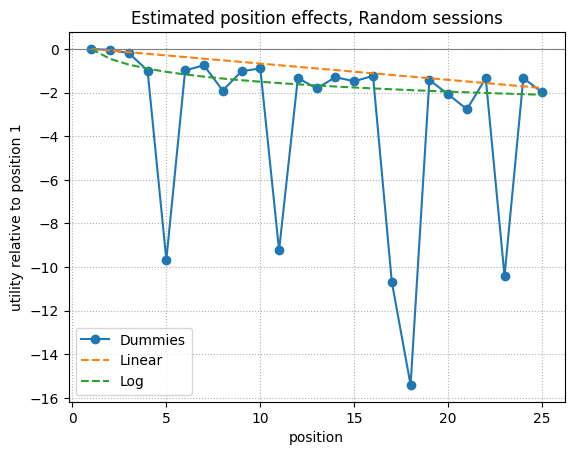

In [138]:
th_lin = pd.Series(res_base_rand_lin.x, ['log_price', 'stars', 'position_num', 'constant'])
th_log = pd.Series(res_base_rand_log.x, ['log_price', 'stars', 'position_log', 'constant'])
th_dum = pd.Series(res_base_rand_dum.x, ['log_price', 'stars', 'constant'] + dummy_cols)

r = np.arange(1, 26)                                                          # positions 1-25
coef_dum = np.r_[0.0, th_dum[[f'pos_{k}' for k in range(2, 26)]].values]     # position 1 = 0 (base)

plt.plot(r, coef_dum, 'o-', label='Dummies')
plt.plot(r, th_lin['position_num'] * (r - 1), '--', label='Linear')          # normalized to 0 at position 1
plt.plot(r, th_log['position_log'] * np.log(r), '--', label='Log')            # log(1) = 0 already
plt.axhline(0, color='grey', lw=0.8)
plt.xlabel('position')
plt.ylabel('utility relative to position 1')
plt.title('Estimated position effects, Random sessions')
plt.legend(); plt.grid(linestyle=':')
plt.show()

In [139]:
# filter on random_bool = 0, i.e. the defualt ranking subsample
df_def = df[df['random_bool'] == 0]
I_chosen_def = df_def['booking_bool'] == 1

### Default with linear position

# chose beta variables to include
xvars = ['log_price', 'stars', 'position_num', 'constant']
X_def_lin = df_def[xvars].astype(float)

res_base_def_lin = minimize(loglike, np.zeros(len(xvars)), args=(X_def_lin, I_chosen_def), method='BFGS')
print(res_base_def_lin.message)
print("Default ranking subsample estimates:")
pd.Series(res_base_def_lin.x, xvars).round(3)

### default with log position

# chose beta variables to include
xvars = ['log_price', 'stars', 'position_log', 'constant']
X_def_log = df_def[xvars].astype(float)

res_base_def_log = minimize(loglike, np.zeros(len(xvars)), args=(X_def_log, I_chosen_def), method='BFGS')
print(res_base_def_log.message)
print("Default ranking subsample estimates:")
pd.Series(res_base_def_log.x, xvars).round(3)

### default with position dummies
dummy_cols = list(dummies.columns)  

xvars = ['log_price', 'stars', 'constant'] + dummy_cols
X_def_dum = df_def[xvars].astype(float)

res_base_def_dum = minimize(loglike, np.zeros(len(xvars)), args=(X_def_dum, I_chosen_def), method='BFGS')
print(res_base_def_dum.message)
print("Default ranking subsample estimates:")
#pd.Series(res_base_def_dum.x, xvars).round(3)

Optimization terminated successfully.
Default ranking subsample estimates:
Optimization terminated successfully.
Default ranking subsample estimates:
Optimization terminated successfully.
Default ranking subsample estimates:


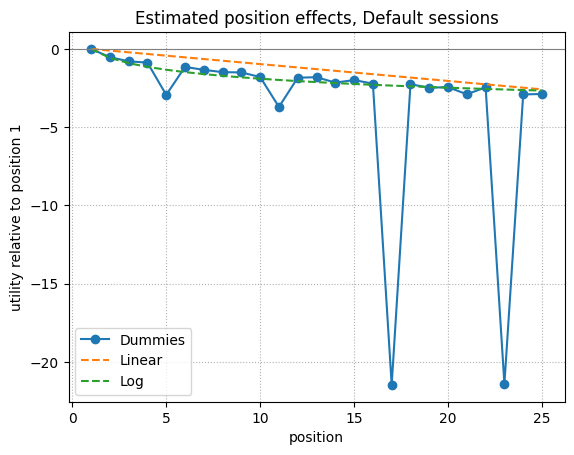

In [140]:
th_lin = pd.Series(res_base_def_lin.x, ['log_price', 'stars', 'position_num', 'constant'])
th_log = pd.Series(res_base_def_log.x, ['log_price', 'stars', 'position_log', 'constant'])
th_dum = pd.Series(res_base_def_dum.x, ['log_price', 'stars', 'constant'] + dummy_cols)

r = np.arange(1, 26)                                                          # positions 1-25
coef_dum = np.r_[0.0, th_dum[[f'pos_{k}' for k in range(2, 26)]].values]     # position 1 = 0 (base)

plt.plot(r, coef_dum, 'o-', label='Dummies')
plt.plot(r, th_lin['position_num'] * (r - 1), '--', label='Linear')          # normalized to 0 at position 1
plt.plot(r, th_log['position_log'] * np.log(r), '--', label='Log')            # log(1) = 0 already
plt.axhline(0, color='grey', lw=0.8)
plt.xlabel('position')
plt.ylabel('utility relative to position 1')
plt.title('Estimated position effects, Default sessions')
plt.legend(); plt.grid(linestyle=':')
plt.show()

### Testing using both random and default data

In [141]:
# both random and default with default dummy (absorbs the level difference)
I_chosen = df['booking_bool'] == 1

# chose beta variables to include
xvars_both = ['log_price', 'stars', 'position_log', 'default_dum', 'constant']
X_both = df[xvars_both].astype(float)

res_base_both = minimize(loglike, np.zeros(len(xvars_both)), args=(X_both, I_chosen), method='BFGS')
print(res_base_both.message)
print("Both rankings  estimates:")
pd.Series(res_base_both.x, xvars_both).round(3)

Optimization terminated successfully.
Both rankings  estimates:


log_price      -0.891
stars           0.265
position_log   -0.815
default_dum     4.647
constant        0.023
dtype: float64

In [142]:
# both random and default with default dummy (absorbs the level difference) and position interaction term (allows for different position effects)
I_chosen = df['booking_bool'] == 1

# chose beta variables to include
xvars_both = ['log_price', 'stars', 'position_log', 'default_dum', 'default_dum_x_position_log', 'constant']
X_both = df[xvars_both].astype(float)

res_base_both = minimize(loglike, np.zeros(len(xvars_both)), args=(X_both, I_chosen), method='BFGS')
print(res_base_both.message)
print("Both rankings  estimates:")
pd.Series(res_base_both.x, xvars_both).round(3)

Optimization terminated successfully.
Both rankings  estimates:


log_price                    -0.888
stars                         0.261
position_log                 -0.657
default_dum                   4.924
default_dum_x_position_log   -0.169
constant                     -0.238
dtype: float64

In [143]:
# both random and default with default dummy (absorbs the level difference) and position interaction term (allows for different position effects) and stars interaction term (as this differs from the random estimates)
I_chosen = df['booking_bool'] == 1

# chose beta variables to include
xvars_both = ['log_price', 'stars', 'position_log', 'default_dum', 'default_dum_x_position_log', 'default_dum_x_stars', 'constant']
X_both = df[xvars_both].astype(float)

res_base_both = minimize(loglike, np.zeros(len(xvars_both)), args=(X_both, I_chosen), method='BFGS')
print(res_base_both.message)
print("Both rankings  estimates:")
pd.Series(res_base_both.x, xvars_both).round(3)

Optimization terminated successfully.
Both rankings  estimates:


log_price                    -0.890
stars                         0.362
position_log                 -0.653
default_dum                   5.288
default_dum_x_position_log   -0.174
default_dum_x_stars          -0.111
constant                     -0.557
dtype: float64

In [144]:
### Random 
# filter on random_bool = 1, i.e. the random ranking subsample
df_rand = df[df['random_bool'] == 1]
I_chosen_rand = df_rand['booking_bool'] == 1

# chose beta variables to include
xvars = ['log_price', 'stars', 'position_log', 'constant']
X_rand = df_rand[xvars].astype(float)

res_base_rand = minimize(loglike, np.zeros(len(xvars)), args=(X_rand, I_chosen_rand), method='BFGS')
print(res_base_rand.message)
print("Random ranking subsample estimates:")
pd.Series(res_base_rand.x, xvars).round(3)

Optimization terminated successfully.
Random ranking subsample estimates:


log_price      -0.867
stars           0.354
position_log   -0.653
constant       -0.639
dtype: float64

In [145]:
### defualt 
# filter on random_bool = 1, i.e. the random ranking subsample
df_def = df[df['random_bool'] == 0]
I_chosen_def = df_def['booking_bool'] == 1

# chose beta variables to include
xvars = ['log_price', 'stars', 'position_log', 'constant']
X_def = df_def[xvars].astype(float)

res_base_def = minimize(loglike, np.zeros(len(xvars)), args=(X_def, I_chosen_def), method='BFGS')
print(res_base_def.message)
print("Default ranking subsample estimates:")
pd.Series(res_base_def.x, xvars).round(3)

Optimization terminated successfully.
Default ranking subsample estimates:


log_price      -0.894
stars           0.252
position_log   -0.827
constant        4.746
dtype: float64

# Estimating the chosen baseline model
This model uses log_postition and random ranking data

In [ ]:
### Random 
# filter on random_bool = 1, i.e. the random ranking subsample
df_rand = df[df['random_bool'] == 1]
I_chosen_rand = df_rand['booking_bool'] == 1

# chose beta variables to include
xvars = ['log_price', 'stars', 'position_log', 'revi','constant']
X_rand = df_rand[xvars].astype(float)

res_baseline = minimize(loglike, np.zeros(len(xvars)), args=(X_rand, I_chosen_rand), method='BFGS')
print(res_baseline.message)
print("Random ranking subsample estimates:")
theta_baseline = pd.Series(res_baseline.x, xvars).round(3)
theta_baseline

Optimization terminated successfully.
Random ranking subsample estimates:


log_price      -0.867
stars           0.354
position_log   -0.653
constant       -0.639
dtype: float64

In [158]:
### Function that finds price equivalent to a change in position, given the estimated coefficients and the price coefficient.
def price_change(theta, pos):
    delta_pos = np.log(pos-1) - np.log(pos)
    return - theta['position_log']/theta['log_price'] * delta_pos


In [170]:
positions = range(2, 26)
dlogp = np.array([price_change(theta_baseline, pos) for pos in positions])

table = pd.DataFrame({
    'Move': [f'{p} → {p-1}' for p in positions],
    'Δ log price': dlogp.round(3),
    'Price increase (%)': (100 * (np.exp(dlogp) - 1)).round(1),
}).set_index('Move')

table

,Δ log price,Price increase (%)
Move,,
2 → 1,0.522,68.5
3 → 2,0.305,35.7
4 → 3,0.217,24.2
5 → 4,0.168,18.3
6 → 5,0.137,14.7
7 → 6,0.116,12.3
8 → 7,0.101,10.6
9 → 8,0.089,9.3
10 → 9,0.079,8.3


## compute the markup

$\eta_j = p_j \cdot L_j = \frac{p_j}{\alpha(1-s_j)}$

In [171]:
# predict the shares (choice probabilities) s_j 
def predict_shares(theta, d):
    """
    theta: pd.Series of estimates, indexed by variable name (e.g. pd.Series(res.x, xvars))
    d:     long data with index (i, j), including the outside rows (j = 0)
    returns: pd.Series of s_ij, one per row
    """
    v = d[list(theta.index)].astype(float) @ theta.values          # utility x_ij' theta (outside rows: 0)
    v = v - v.groupby(level='i').transform('max')                  # for numerical stability; shares unchanged
    ev = np.exp(v)
    return ev / ev.groupby(level='i').transform('sum')             # logit share within each session

In [190]:
d = df_rand.copy()                                   # the data you estimated on (with outside rows)

d['s'] = predict_shares(theta_baseline, d)

# checks
hotels = d[d.index.get_level_values('j') > 0].copy()

hotels['markup'] = hotels['price_usd'] / (-theta_baseline['log_price'] * (1 - hotels['s']))

hotels['lerner'] = hotels['markup'] / hotels['price_usd']     # (p − c)/p, ≈ 1/α
hotels['mc']     = hotels['price_usd'] - hotels['markup']      # implied marginal cost

hotels[['price_usd', 'markup', 'lerner', 'mc']].agg(['mean', 'median']).round(2)

,price_usd,markup,lerner,mc
mean,167.79,194.36,1.16,-26.57
median,125.00,145.10,1.16,-19.98
